# Project: Classification, Regression and Predicting high site traffic

## 1 Preliminaries: The site traffic data

The data are from a website for cooking recipes. The company that owns the website wants to sell subscriptions, and the idea is that if the website receives lots of visits (so traffic is “high”) because of a posted recipe, the likelihood of a subscription sale increases.

Hence the overall objective of this project is to predict which recipes will lead to high traffic.

The raw data set for this project is **"recipe_site_traffic_2212.csv"**.

| Variable      | Explanation |
|---------------|-------------|
| recipe        | Unique identifier of recipe |
| calories      | Number of calories |
| carbohydrate  | Amount of carbohydrates in grams |
| sugar         | Amount of sugar in grams |
| protein       | Amount of protein in grams |
| category      | Type of recipe. Recipes are listed in one of ten possible groupings: *Lunch/Snacks*, *Beverages*, *Potato*, *Vegetable*, *Meat*, *Chicken*, *Pork*, *Dessert*, *Breakfast*, *One Dish Meal*. |
| servings      | Number of servings for the recipe |
| high_traffic  | If the traffic to the site was high when this recipe was shown, this is marked with **"High"**. |


For instance, a data row codes a recipe, say for “tomato soup” as: the number of servings, the category, and the nutritional breakdown. Not recorded are, for instance, the actual cooking ingredients necessary for the recipe, or the required preparation time. The response variable is , indicating whether this recipe generated low or high site traffic / number of visits on the website.high_traffic.

In [140]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

In [141]:
df = pd.read_csv("recipe_site_traffic_2212.csv", sep=";")

print(df.shape)
print(df.dtypes)
print("Doublons (lignes) :", df.duplicated().sum())
print("recipe unique :", df['recipe'].is_unique)
print("Valeurs de high_traffic :", df['high_traffic'].unique())
print(df['category'].nunique(), "catégories")
df.head()

(947, 8)
recipe            int64
calories        float64
carbohydrate    float64
sugar           float64
protein         float64
category         object
servings         object
high_traffic     object
dtype: object
Doublons (lignes) : 0
recipe unique : True
Valeurs de high_traffic : ['High' nan]
11 catégories


,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


In [142]:
df['high_traffic'] = df['high_traffic'].fillna('Low')
assert set(df['high_traffic'].unique()) == {'High', 'Low'}

df['high_traffic'] = df['high_traffic'].map({'High': 1, 'Low': 0})

In [143]:
print(df['category'].value_counts())

df['category'] = df['category'].replace({'Chicken Breast': 'Chicken'})

print(df['category'].nunique(), "catégories après fusion")  # doit afficher 10

category
Breakfast         106
Chicken Breast     98
Beverages          92
Lunch/Snacks       89
Potato             88
Pork               84
Vegetable          83
Dessert            83
Meat               79
Chicken            74
One Dish Meal      71
Name: count, dtype: int64
10 catégories après fusion


In [144]:
df['servings'].value_counts()

servings
4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: count, dtype: int64

In [145]:
df['servings'] = df['servings'].astype(str).str.extract(r'(\d+)')[0].astype(int)

print(df['servings'].value_counts().sort_index())
print(df['servings'].dtype)

servings
1    175
2    183
4    391
6    198
Name: count, dtype: int64
int64


In [146]:
nutri_cols = ['calories', 'carbohydrate', 'sugar', 'protein']

# Résumé des manquants (avant imputation)
missing_summary = pd.DataFrame({
    "Missing Count": df[nutri_cols].isna().sum(),
    "Missing %": (df[nutri_cols].isna().mean() * 100).round(2)
})
print(missing_summary)

# Les 4 colonnes sont-elles manquantes sur les mêmes lignes ?
print("Lignes avec les 4 manquants :", df[nutri_cols].isna().all(axis=1).sum())

# Indicateur de manquant (garde l'information)
df['nutrition_missing'] = df[nutri_cols].isna().any(axis=1).astype(int)

# Imputation par la médiane de la catégorie
for col in nutri_cols:
    df[col] = df[col].fillna(df.groupby('category')[col].transform('median'))

print("NaN restants :", df[nutri_cols].isna().sum().sum())

              Missing Count  Missing %
calories                 52       5.49
carbohydrate             52       5.49
sugar                    52       5.49
protein                  52       5.49
Lignes avec les 4 manquants : 52
NaN restants : 0


In [147]:
print(df.groupby('nutrition_missing')['high_traffic'].agg(['mean', 'count']))

                       mean  count
nutrition_missing                 
0                  0.597765    895
1                  0.750000     52


In [148]:
print(pd.crosstab(df['category'], df['nutrition_missing']))

# Taux de high traffic par catégorie ET par statut manquant
print(df.groupby(['category', 'nutrition_missing'])['high_traffic'].agg(['mean', 'count']).round(2))

nutrition_missing    0   1
category                  
Beverages           92   0
Breakfast          106   0
Chicken            163   9
Dessert             77   6
Lunch/Snacks        82   7
Meat                74   5
One Dish Meal       67   4
Pork                73  11
Potato              83   5
Vegetable           78   5
                                 mean  count
category      nutrition_missing             
Beverages     0                  0.05     92
Breakfast     0                  0.31    106
Chicken       0                  0.42    163
              1                  0.44      9
Dessert       0                  0.62     77
              1                  0.83      6
Lunch/Snacks  0                  0.63     82
              1                  0.71      7
Meat          0                  0.76     74
              1                  0.60      5
One Dish Meal 0                  0.76     67
              1                  0.25      4
Pork          0                  0.90     73
 

In [149]:
from scipy.stats import chi2_contingency

ct = pd.crosstab(df['nutrition_missing'], df['high_traffic'])
chi2, p, dof, _ = chi2_contingency(ct)
print(f"Chi² = {chi2:.2f} | p = {p:.4f}")

Chi² = 4.15 | p = 0.0415


In [150]:
df.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic,nutrition_missing
0,1,399.26,19.56,5.23,29.82,Pork,6,1,1
1,2,35.48,38.56,0.66,0.92,Potato,4,1,0
2,3,914.28,42.68,3.09,2.88,Breakfast,1,0,0
3,4,97.03,30.56,38.63,0.02,Beverages,4,1,0
4,5,27.05,1.85,0.80,0.53,Beverages,4,0,0


In [151]:
df.isna().sum()

recipe               0
calories             0
carbohydrate         0
sugar                0
protein              0
category             0
servings             0
high_traffic         0
nutrition_missing    0
dtype: int64

In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   recipe             947 non-null    int64  
 1   calories           947 non-null    float64
 2   carbohydrate       947 non-null    float64
 3   sugar              947 non-null    float64
 4   protein            947 non-null    float64
 5   category           947 non-null    object 
 6   servings           947 non-null    int64  
 7   high_traffic       947 non-null    int64  
 8   nutrition_missing  947 non-null    int64  
dtypes: float64(4), int64(4), object(1)
memory usage: 66.7+ KB


## 2. Exploratory Data Analysis (EDA)

In [153]:
df.drop(columns='recipe').describe()

,calories,carbohydrate,sugar,protein,servings,high_traffic,nutrition_missing
count,947.000000,947.000000,947.000000,947.000000,947.000000,947.000000,947.000000
mean,431.085544,34.449625,8.888728,23.938786,3.477297,0.606125,0.054910
std,441.366521,42.846480,14.371911,35.473402,1.732741,0.488866,0.227925
min,0.140000,0.030000,0.010000,0.000000,1.000000,0.000000,0.000000
25%,114.410000,9.135000,1.795000,3.465000,2.000000,0.000000,0.000000
50%,296.920000,21.190000,4.400000,11.240000,4.000000,1.000000,0.000000
75%,576.225000,42.590000,9.565000,29.820000,4.000000,1.000000,0.000000
max,3633.160000,530.420000,148.750000,363.360000,6.000000,1.000000,1.000000


Univarié, cible et catégories

high_traffic
1    0.606
0    0.394
Name: proportion, dtype: float64


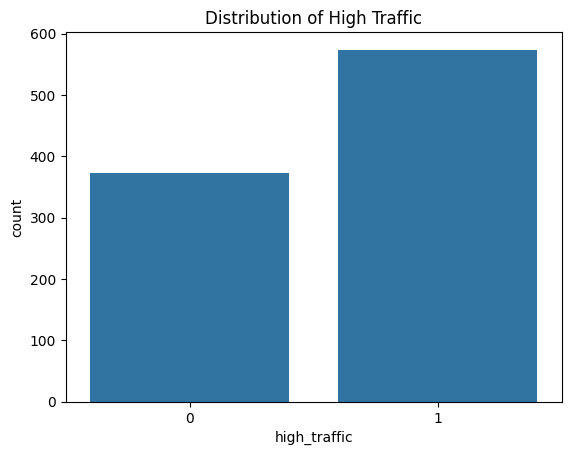

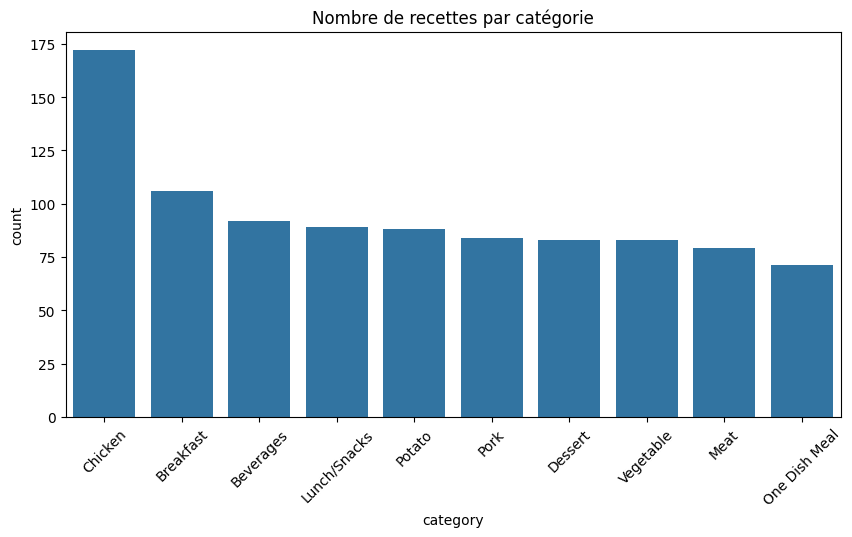

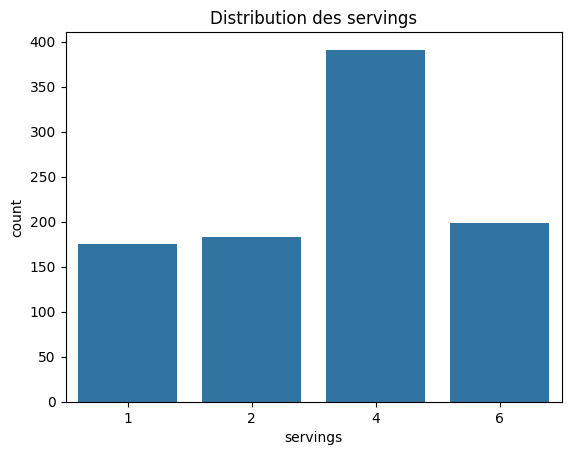

In [154]:
# Cible
print(df['high_traffic'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='high_traffic')
plt.title("Distribution of High Traffic")
plt.show()

# Catégories
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='category', order=df['category'].value_counts().index)
plt.xticks(rotation=45)
plt.title("Nombre de recettes par catégorie")
plt.show()

# Servings
sns.countplot(data=df, x='servings')
plt.title("Distribution des servings")
plt.show()

Univarié, variables numériques (avec log)

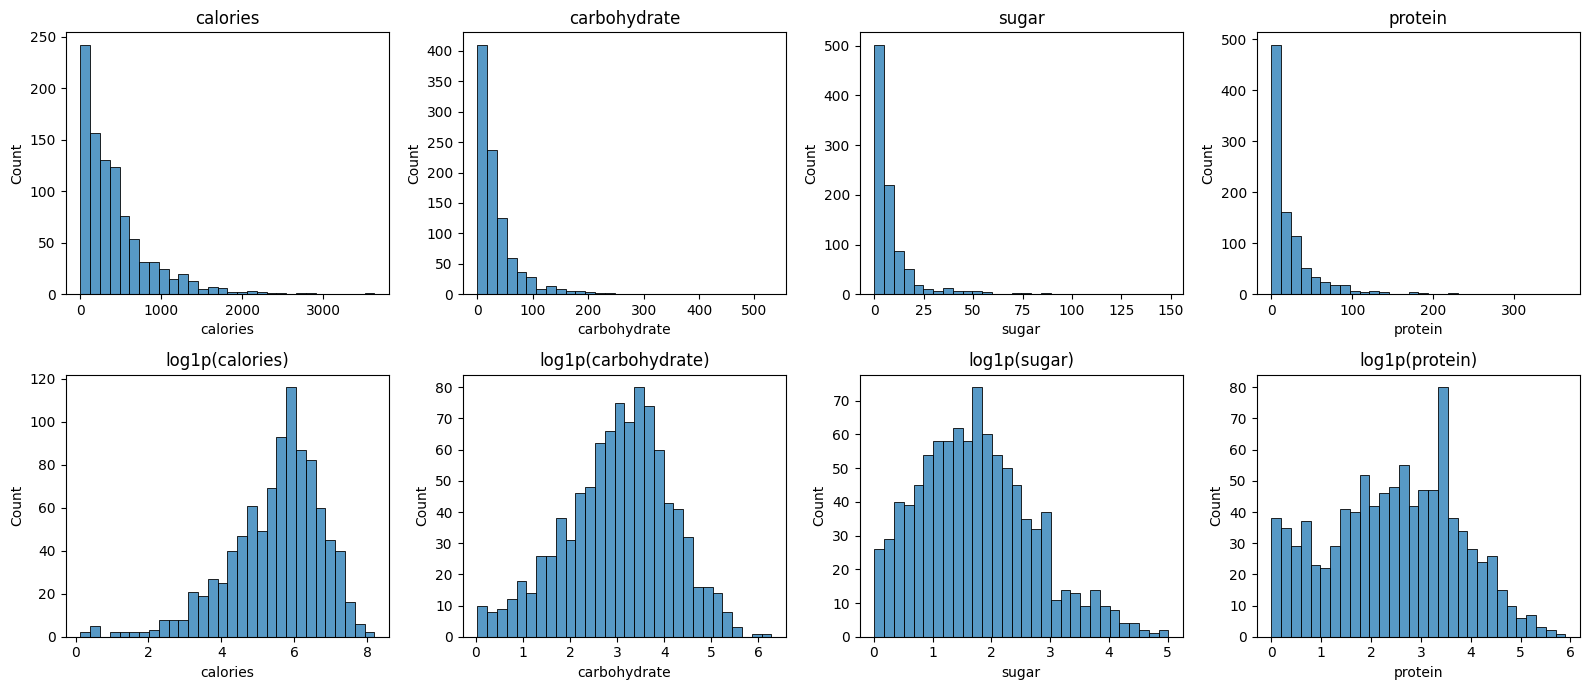

skewness of nutritional columns:
calories        2.11
carbohydrate    3.87
sugar           4.29
protein         3.59
dtype: float64


In [155]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, col in enumerate(nutri_cols):
    sns.histplot(df[col], bins=30, ax=axes[0, i])
    axes[0, i].set_title(col)
    sns.histplot(np.log1p(df[col]), bins=30, ax=axes[1, i])
    axes[1, i].set_title(f"log1p({col})")

plt.tight_layout()
plt.show()

print("skewness of nutritional columns:")

print(df[nutri_cols].skew().round(2))

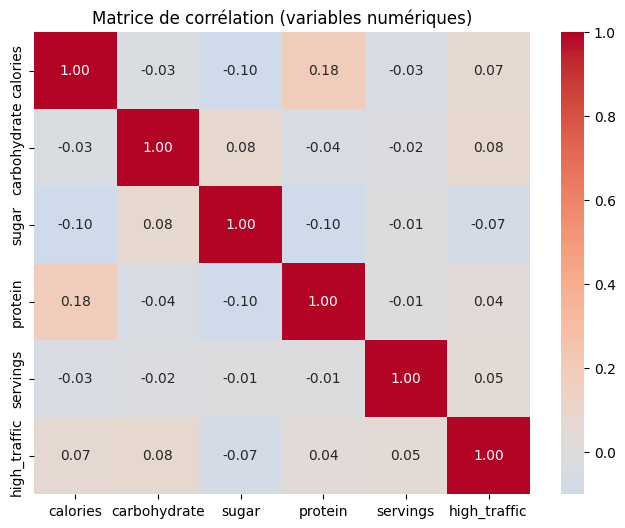

In [156]:
corr = df[nutri_cols + ['servings', 'high_traffic']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title("Matrice de corrélation (variables numériques)")
plt.show()

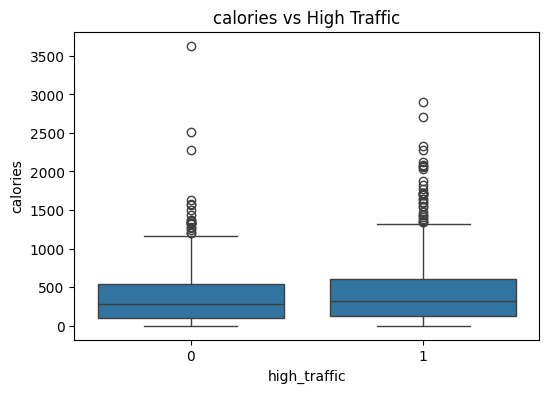

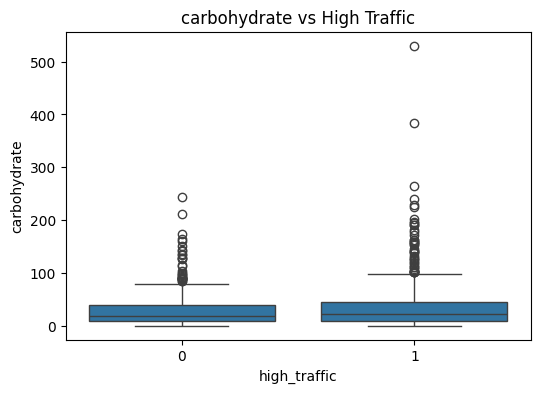

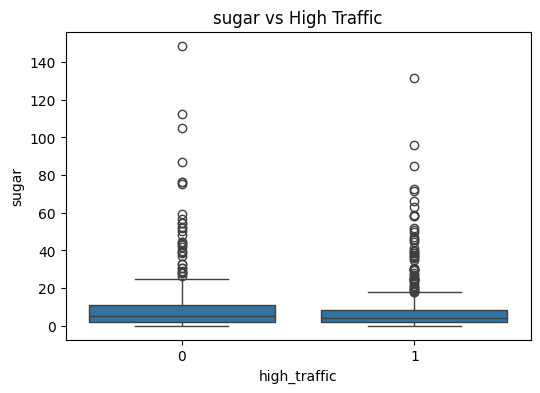

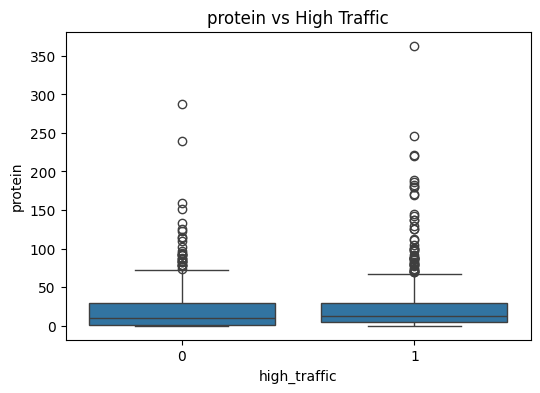

calories      | statistique =     115214 | p = 0.0472
carbohydrate  | statistique =     115446 | p = 0.0412
sugar         | statistique =      98956 | p = 0.0491
protein       | statistique =     120705 | p = 0.0009


In [157]:
for col in nutri_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x='high_traffic', y=col)
    plt.title(f'{col} vs High Traffic')
    plt.show()

# Test de Mann-Whitney (adapté aux distributions asymétriques)
for col in nutri_cols:
    high = df.loc[df['high_traffic'] == 1, col]
    low = df.loc[df['high_traffic'] == 0, col]
    stat, p = mannwhitneyu(high, low)
    print(f"{col:13s} | statistique = {stat:10.0f} | p = {p:.4f}")

servings
1    58.86
2    57.38
4    60.61
6    65.15
Name: high_traffic, dtype: float64


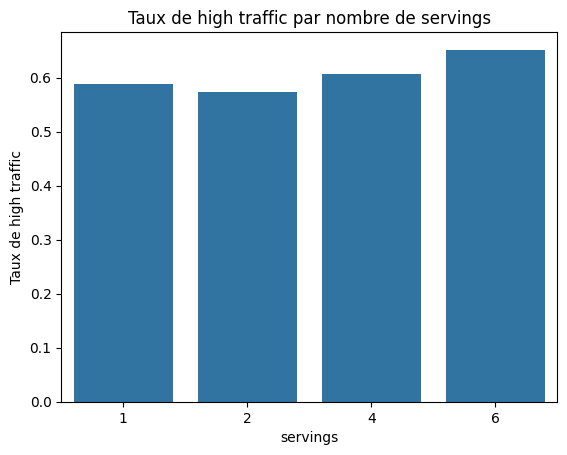

Chi² = 2.74 | p = 0.4340


In [158]:
rate_servings = df.groupby('servings')['high_traffic'].mean() * 100
print(rate_servings.round(2))

sns.barplot(data=df, x='servings', y='high_traffic', errorbar=None)
plt.ylabel("Taux de high traffic")
plt.title("Taux de high traffic par nombre de servings")
plt.show()

# Chi² servings vs cible
ct = pd.crosstab(df['servings'], df['high_traffic'])
chi2, p, dof, _ = chi2_contingency(ct)
print(f"Chi² = {chi2:.2f} | p = {p:.4f}")

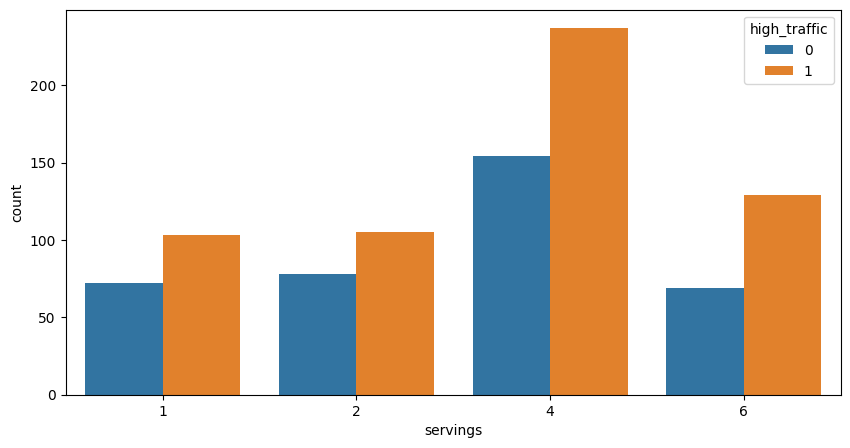

In [159]:
plt.figure(figsize=(10, 5))
pd.crosstab(
    df['servings'],
    df['high_traffic'],
    normalize='index'
) * 100

sns.countplot(
    data=df,
    x='servings',
    hue='high_traffic'
    #rotate=45
)

plt.show()


Chi² = 318.29 | dof = 9 | p = 3.417e-63
V de Cramér = 0.580
category
Vegetable        98.80
Potato           94.32
Pork             91.67
Meat             74.68
One Dish Meal    73.24
Lunch/Snacks     64.04
Dessert          63.86
Chicken          42.44
Breakfast        31.13
Beverages         5.43
Name: high_traffic, dtype: float64


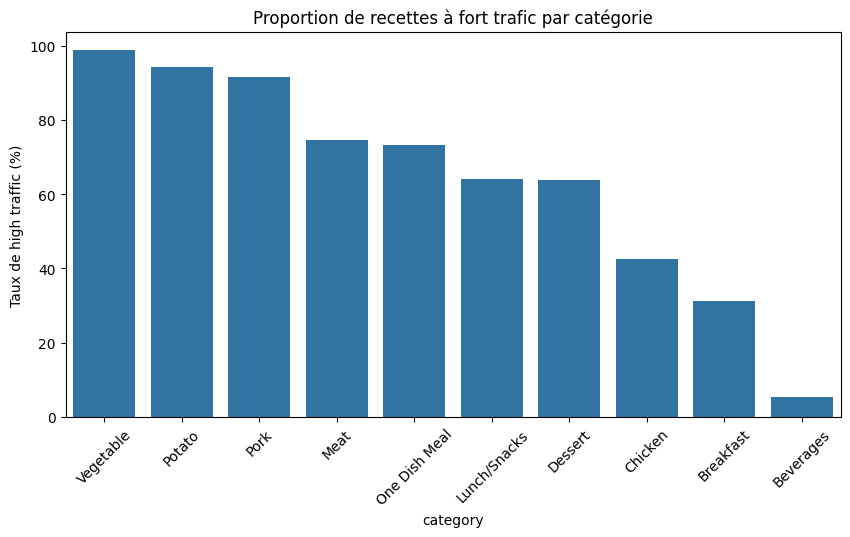

In [160]:
ct = pd.crosstab(df['category'], df['high_traffic'])
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print(f"Chi² = {chi2:.2f} | dof = {dof} | p = {p:.4g}")
print(f"V de Cramér = {cramers_v:.3f}")

traffic_rate = (df.groupby('category')['high_traffic']
                  .mean().sort_values(ascending=False) * 100)
print(traffic_rate.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(x=traffic_rate.index, y=traffic_rate.values)
plt.xticks(rotation=45)
plt.ylabel("Taux de high traffic (%)")
plt.title("Proportion de recettes à fort trafic par catégorie")
plt.show()

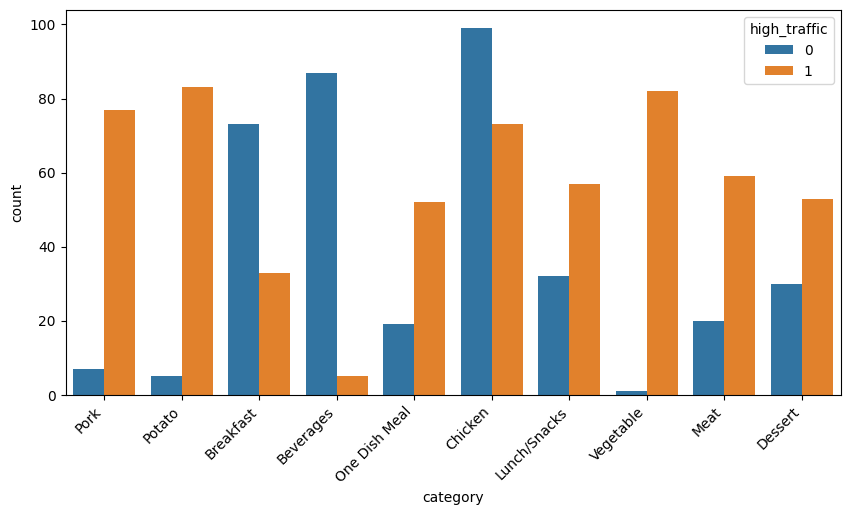

In [161]:
plt.figure(figsize=(10, 5))
pd.crosstab(
    df['category'],
    df['high_traffic'],
    normalize='index'
) * 100

sns.countplot(
    data=df,
    x='category',
    hue='high_traffic'
)
plt.xticks(rotation=45, ha='right')
plt.show()

Modelisation

In [162]:
nutri_cols = ['calories', 'carbohydrate', 'sugar', 'protein']
num_cols = nutri_cols + ['servings']
cat_cols = ['category']

X = df[num_cols + cat_cols]
y = df['high_traffic']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(757, 6) (190, 6)
0.606 0.605


In [166]:
# Pour la régression logistique : log1p sur la nutrition + standardisation + one-hot
log_cols = nutri_cols
prep_linear = ColumnTransformer([
    ('log_scale', Pipeline([
        (('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))),
        ('scale', StandardScaler())
    ]), log_cols),
    ('scale', StandardScaler(), ['servings']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Pour les modèles à base d'arbres : pas de scaling, juste le one-hot
prep_tree = ColumnTransformer([
    ('pass', 'passthrough', nutri_cols + ['servings']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

In [167]:
models = {
    'Logistic Regression': Pipeline([
        ('prep', prep_linear),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', prep_tree),
        ('clf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
    ]),
    'Gradient Boosting': Pipeline([
        ('prep', prep_tree),
        ('clf', GradientBoostingClassifier(random_state=42))
    ])
}

In [168]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {m: scores[f'test_{m}'].mean() for m in scoring}

cv_df = pd.DataFrame(cv_results).T.round(3)
cv_df

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.757,0.795,0.815,0.803,0.811
Random Forest,0.724,0.750,0.819,0.782,0.795
Gradient Boosting,0.709,0.741,0.806,0.771,0.779


In [169]:
param_grids = {
    'Logistic Regression': {
        'clf__C': [0.01, 0.1, 1, 10]
    },
    'Random Forest': {
        'clf__n_estimators': [200, 400],
        'clf__max_depth': [None, 5, 10],
        'clf__min_samples_leaf': [1, 3, 5]
    },
    'Gradient Boosting': {
        'clf__n_estimators': [100, 200],
        'clf__learning_rate': [0.05, 0.1],
        'clf__max_depth': [2, 3, 4]
    }
}

best_models = {}
for name, model in models.items():
    gs = GridSearchCV(model, param_grids[name], cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(f"{name:20s} | meilleur f1 CV = {gs.best_score_:.3f} | {gs.best_params_}")

Logistic Regression  | meilleur f1 CV = 0.803 | {'clf__C': 1}
Random Forest        | meilleur f1 CV = 0.796 | {'clf__max_depth': 5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}
Gradient Boosting    | meilleur f1 CV = 0.801 | {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 100}


In [170]:
rows = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Modèle': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba)
    })

results = pd.DataFrame(rows).set_index('Modèle').round(3)
results

,Accuracy,Precision,Recall,F1,ROC AUC
Modèle,,,,,
Logistic Regression,0.779,0.848,0.774,0.809,0.869
Random Forest,0.753,0.788,0.809,0.798,0.852
Gradient Boosting,0.779,0.854,0.765,0.807,0.850


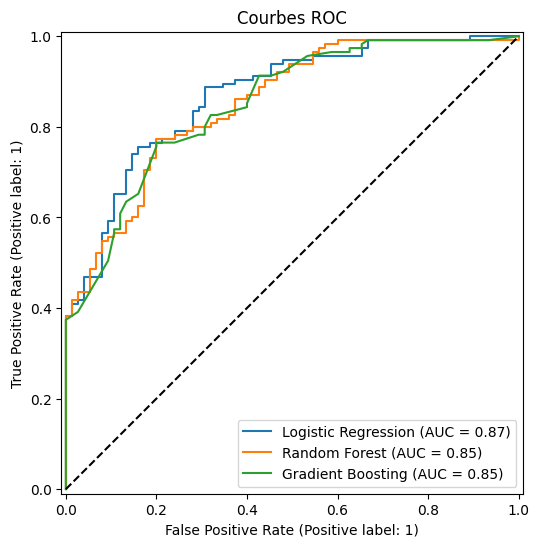

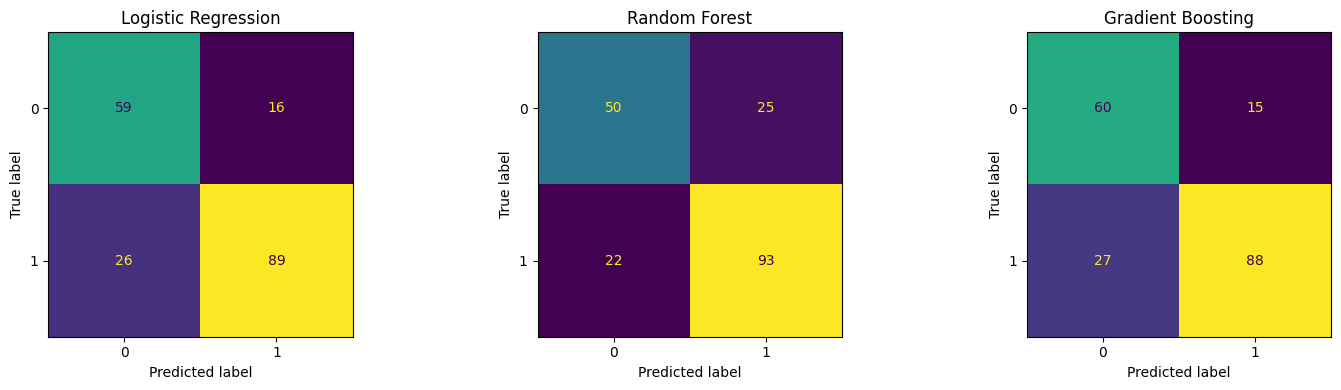

Meilleur modèle : Logistic Regression
              precision    recall  f1-score   support

           0       0.69      0.79      0.74        75
           1       0.85      0.77      0.81       115

    accuracy                           0.78       190
   macro avg       0.77      0.78      0.77       190
weighted avg       0.79      0.78      0.78       190



In [171]:
# Courbes ROC superposées
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Hasard')
ax.set_title("Courbes ROC")
plt.show()

# Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Rapport détaillé du meilleur modèle
best_name = results['F1'].idxmax()
print("Meilleur modèle :", best_name)
print(classification_report(y_test, best_models[best_name].predict(X_test)))

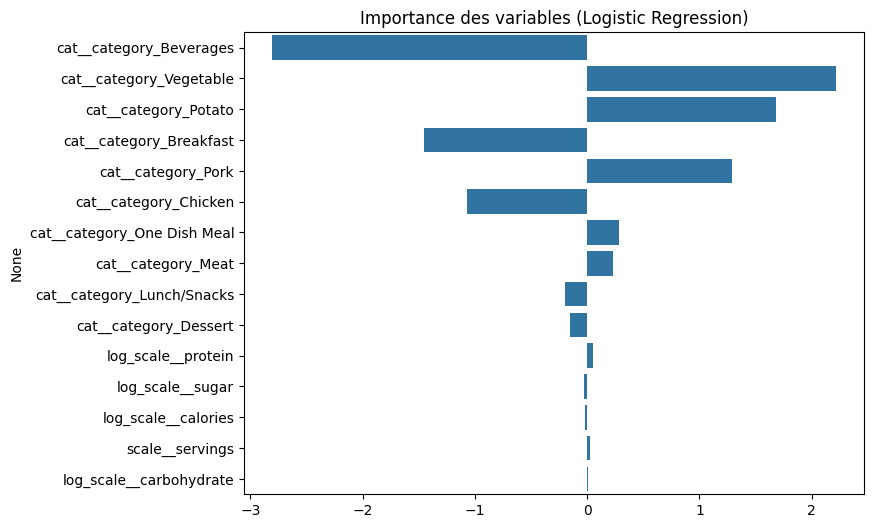

In [172]:
best = best_models[best_name]
feature_names = best.named_steps['prep'].get_feature_names_out()
clf = best.named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    imp = pd.Series(clf.feature_importances_, index=feature_names)
else:  # régression logistique : coefficients
    imp = pd.Series(clf.coef_[0], index=feature_names)

imp = imp.reindex(imp.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index)
plt.title(f"Importance des variables ({best_name})")
plt.show()

In [174]:
# Exemple : 2 nouvelles recettes
#nouvelles = pd.DataFrame({
 #   'calories': [250, 600],
 #   'carbohydrate': [20, 55],
 #   'sugar': [3, 25],
 #   'protein': [15, 30],
 #   'servings': [4, 2],
 #   'nutrition_missing': [0, 0],
 #   'category': ['Vegetable', 'Dessert']
#})

#proba = best.predict_proba(nouvelles)[:, 1]
#pred = best.predict(nouvelles)

#resultat = nouvelles.copy()
#resultat['proba_high_traffic'] = proba.round(3)
#resultat['prediction'] = np.where(pred == 1, 'High', 'Low')
#resultat

In [ ]:
#import joblib
#joblib.dump(best, "best_model_recipes.joblib")

# Rechargement
# model = joblib.load("best_model_recipes.joblib")